<a href="https://colab.research.google.com/github/sebastianvettel1212/Scikit-Learn-Cookbook/blob/main/scikit_learn_Cookbook_Chapter13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 13 — *Deploying* Model scikit-learn ke Produksi (*Deploying scikit-learn Models in Production*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 13 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel. Perbaikan paling umum: kode buku memakai angka acak NumPy tanpa *seed* (hasil tidak bisa direproduksi) dan mencatat versi scikit-learn secara *hard-coded* (`"1.3.2"`); di sini diganti dengan `np.random.seed(2024)` dan `sklearn.__version__`. (Teks pembuka notebook resmi Bab 13 menyebut "cross-validation and model evaluation", yang keliru: bab ini membahas *deployment*.)
>
> Sel-sel di bab ini membuat beberapa berkas di folder kerja (mis. `model.joblib`, `rf_v1.0.joblib`). Angka **waktu** (detik) bergantung pada mesin Anda.

---

## Daftar Isi
0. Persiapan
1. Menyimpan Model (*Persisting Models*)
2. Serialisasi Model: *pickle* vs *joblib*
3. Skala dan Performa Inferensi (*Scaling and Performance*)
4. Memantau dan Memperbarui Model (*Monitoring and Updating Models*)
5. Versioning dan Siklus Hidup Model (*Model Versioning and Lifecycle*)
6. *Pipeline* Deployment dan Pemeriksaan Otomatis (*Deployment Pipelines and Automated Checks*)
7. Latihan Praktik
8. Ringkasan Bab

---

## Pengantar
Model yang akurat di notebook belum berguna sebelum **dipakai**. *Deployment* berarti memindahkan model dari lingkungan pengembangan ke produksi, sehingga pengguna atau sistem lain dapat memperoleh prediksinya. Pekerjaannya tidak berhenti pada "menyimpan model": diperlukan **artefak yang andal**, **penyajian** dengan latensi dan *throughput* yang memadai, serta **pemantauan** agar model tetap baik ketika data berubah. Siklusnya: **latih → serialisasi → sajikan → pantau → perbarui**. Bab ini menelusuri tiap tahap dengan scikit-learn.

## 0. Persiapan

In [1]:
!pip install numpy pandas scipy scikit-learn matplotlib joblib flask

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print('Versi scikit-learn:', sklearn.__version__, '| jumlah CPU:', os.cpu_count())

Versi scikit-learn: 1.6.1 | jumlah CPU: 2


---
## 1. Menyimpan Model (*Persisting Models*)

### Teori
Model terlatih hanyalah objek Python di memori; ketika proses berakhir, model hilang. ***Persistence*** (serialisasi) menyimpan objek tersebut ke berkas (**artefak**) sehingga dapat dimuat kembali di lingkungan lain tanpa melatih ulang, misalnya di server produksi. Rekomendasi scikit-learn adalah modul **`joblib`**, yang efisien untuk objek berisi array NumPy besar.

Yang tersimpan adalah **parameter yang dipelajari** (mis. `coef_`, struktur pohon) beserta hiperparameter, bukan data latih (kecuali model seperti KNN yang memang menyimpannya).

Tiga peringatan penting:
1. ***Version compatibility*:** artefak sebaiknya dimuat dengan versi scikit-learn **yang sama** dengan saat disimpan; versi berbeda dapat menimbulkan peringatan atau hasil keliru.
2. ***Security*:** `pickle`/`joblib` **mengeksekusi kode saat dimuat**. **Jangan pernah memuat berkas dari sumber yang tidak tepercaya.**
3. **Simpan seluruh *Pipeline***, bukan hanya model, agar praproses (mis. `StandardScaler`) ikut tersimpan dan tidak tertukar saat prediksi.

### Getting ready
Dataset sintetis 1.000 sampel dengan 20 fitur, dan model regresi logistik.

In [3]:
# Load the libraries
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train a simple model
X, y = make_classification(n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)
print('Akurasi pada data latih:', round(clf.score(X, y), 3))

Akurasi pada data latih: 0.879


### How to do it...
Menyimpan model ke disk lalu memuatnya kembali, seolah di lingkungan baru ("persist" artinya menyimpan agar bertahan setelah proses berakhir).

In [4]:
# Save the trained model using joblib
dump(clf, "model.joblib")

# Load the model back
clf_loaded = load("model.joblib")

# Make a prediction with the loaded model
np.random.seed(2024)   # Catatan: ditambahkan agar data masukan acak dapat direproduksi
incoming = np.random.rand(1, 20)
print(clf_loaded.predict(incoming))

[1]


**Interpretasi:** model dilatih (akurasi latih 0,879), disimpan ke `model.joblib`, dimuat kembali, dan langsung dapat memprediksi data baru (keluaran `[1]` = kelas 1) tanpa pelatihan ulang. Inilah inti *persistence*: pelatihan (mahal) dilakukan sekali, lalu hasilnya dipakai berulang kali di lingkungan lain.

### How it works...
`joblib` menyimpan estimator beserta array NumPy-nya secara efisien; saat dimuat, objek yang sama dapat langsung memprediksi tanpa pelatihan ulang. Berikut pembuktian bahwa hasil muat identik dengan aslinya dan pengaruh kompresi.

In [5]:
# Tambahan (tidak ada di kode buku)
print('Koefisien identik persis    :', np.array_equal(clf.coef_, clf_loaded.coef_))
print('Hiperparameter identik      :', clf.get_params() == clf_loaded.get_params())
print('Prediksi 1.000 data identik :', np.array_equal(clf.predict(X), clf_loaded.predict(X)))
print('Probabilitas identik        :', np.allclose(clf.predict_proba(X), clf_loaded.predict_proba(X)))

dump(clf, "model_compressed.joblib", compress=3)
print(f'Ukuran berkas: tanpa kompresi = {os.path.getsize("model.joblib"):,} byte | compress=3 = {os.path.getsize("model_compressed.joblib"):,} byte')
print('Isi berkas = parameter hasil belajar, bentuk coef_:', clf.coef_.shape, '+ intercept_:', clf.intercept_.shape)

Koefisien identik persis    : True
Hiperparameter identik      : True
Prediksi 1.000 data identik : True
Probabilitas identik        : True
Ukuran berkas: tanpa kompresi = 1,023 byte | compress=3 = 743 byte
Isi berkas = parameter hasil belajar, bentuk coef_: (1, 20) + intercept_: (1,)


**Interpretasi:** model hasil muat **identik persis** dengan aslinya: koefisien sama bit demi bit, hiperparameter sama, dan prediksi serta probabilitas pada 1.000 data juga sama. Berkas hanya berisi parameter hasil belajar (`coef_` berbentuk (1, 20) dan `intercept_`), sehingga berukuran kecil (1.007 byte); `compress=3` menyusutkannya menjadi 735 byte. Pada model sekecil ini penghematannya tidak berarti, tetapi pada model besar kompresi dapat sangat membantu (lihat subbab 2).

### Key Ideas
- **Persistence** menyimpan model terlatih ke berkas agar dapat dipakai tanpa melatih ulang.
- Pakai **`joblib`** untuk estimator scikit-learn; simpan **seluruh `Pipeline`**.
- Cocokkan **versi scikit-learn** dan **jangan memuat berkas dari sumber yang tidak tepercaya**.

---
## 2. Serialisasi Model: *pickle* vs *joblib*

### Teori
| Aspek | `pickle` (pustaka standar Python) | `joblib` |
|---|---|---|
| Cakupan | objek Python apa pun | objek apa pun, dioptimalkan untuk **array NumPy besar** |
| Ukuran/kecepatan | bisa lambat dan boros memori pada array besar | umumnya lebih cepat dan hemat; mendukung kompresi (`compress=`), *memory-mapping* (`mmap_mode`) |
| Risiko keamanan | memuat = mengeksekusi kode | sama (dibangun di atas `pickle`) |
| Antar-versi/bahasa | rapuh antar versi pustaka; hanya Python | sama |

Karena format ini terikat pada **Python dan versi pustaka**, untuk lintas-bahasa/lintas-platform banyak tim memakai **format terbuka seperti ONNX** (*Open Neural Network Exchange*), yang mengekspor model ke representasi netral sehingga bisa dijalankan oleh runtime lain (mis. `onnxruntime`) tanpa scikit-learn. Konverternya (mis. paket `skl2onnx`) berada di luar scikit-learn, sehingga hanya dibahas konsepnya di sini.

### Getting ready
*Random forest* kecil (10 pohon) pada 500 sampel dengan 15 fitur.

In [6]:
# Load the libraries
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import pickle
from joblib import dump, load

# Train a classifier
X, y = make_classification(n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(n_estimators=10, random_state=2024)
rf.fit(X, y)

RandomForestClassifier(n_estimators=10, random_state=2024)

### How to do it...
Serialisasi dengan `pickle` dan `joblib` sama-sama mudah; setelah dimuat, perilakunya harus identik.

In [7]:
# Serialize using pickle
with open("rf.pkl", "wb") as f:
    pickle.dump(rf, f)

# Serialize using joblib
dump(rf, "rf.joblib")

# Load the pickle model
with open("rf.pkl", "rb") as f:
    rf1 = pickle.load(f)

# Load the joblib model
rf2 = load("rf.joblib")

# Ensure identical behavior after loading
assert np.array_equal(rf.predict(X[:5]), rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]), rf2.predict(X[:5]))
print('Kedua model hasil muat berperilaku identik dengan aslinya (assert lolos).')

Kedua model hasil muat berperilaku identik dengan aslinya (assert lolos).


**Interpretasi:** kedua cara serialisasi menghasilkan model yang berperilaku identik dengan model asli (kedua `assert` lolos). Untuk model kecil seperti ini, pilihan `pickle` atau `joblib` tidak memengaruhi hasil; perbedaannya muncul pada ukuran, kecepatan, dan fitur tambahan (kompresi, *mmap*).

### How it works...
`pickle` adalah serialisasi bawaan Python; `joblib` mengoptimalkan penanganan array NumPy besar yang umum pada estimator. Berikut perbandingan ukuran dan waktu pada model yang lebih besar (200 pohon, 5.000 sampel).

In [8]:
# Tambahan (tidak ada di kode buku)
import time
Xb, yb = make_classification(n_samples=5000, n_features=30, random_state=2024)
big = RandomForestClassifier(n_estimators=200, random_state=2024).fit(Xb, yb)

rows = []
def bench(name, save_fn, load_fn, path):
    t0 = time.perf_counter(); save_fn(path); ts = time.perf_counter() - t0
    t0 = time.perf_counter(); m = load_fn(path); tl = time.perf_counter() - t0
    assert np.array_equal(big.predict(Xb[:200]), m.predict(Xb[:200]))
    rows.append({'Metode': name, 'Ukuran (MB)': os.path.getsize(path) / 1e6, 'Waktu simpan (s)': ts, 'Waktu muat (s)': tl})

bench('pickle', lambda p: pickle.dump(big, open(p, 'wb')), lambda p: pickle.load(open(p, 'rb')), 'big.pkl')
bench('joblib', lambda p: dump(big, p), load, 'big.joblib')
bench('joblib compress=3', lambda p: dump(big, p, compress=3), load, 'big_c3.joblib')
pd.DataFrame(rows).set_index('Metode').round(3)

,Ukuran (MB),Waktu simpan (s),Waktu muat (s)
Metode,,,
pickle,4.862,0.032,0.035
joblib,4.877,0.113,0.132
joblib compress=3,1.160,0.229,0.102


**Interpretasi:** untuk *random forest* 200 pohon: `pickle` ≈ 4,86 MB, `joblib` ≈ 4,88 MB (praktis sama), dan **`joblib compress=3` hanya ≈ 1,16 MB** (≈ 4,2× lebih kecil, hemat sekitar 76%) dengan harga waktu simpan dan muat yang lebih lama (kisaran 0,1 s dan 0,04 s, dibanding sekitar 0,01–0,02 s untuk `pickle`). Jadi pada model ini klaim umum "`joblib` lebih cepat daripada `pickle`" **tidak terlihat**: `pickle` justru tercepat; keunggulan `joblib` sebenarnya terletak pada penanganan array NumPy yang sangat besar, kompresi, dan *memory-mapping*. Pilih kompresi bila ukuran penyimpanan atau transfer lebih penting daripada kecepatan muat. Angka waktu bergantung pada mesin dan berubah sedikit pada tiap eksekusi.

### Key Ideas
- `pickle` dan `joblib` sama-sama mengikat artefak ke **Python dan versi pustaka**; keduanya **tidak aman** untuk berkas tak tepercaya.
- `joblib` memberi opsi **kompresi** dan *memory-mapping* untuk model besar.
- Untuk lintas-bahasa atau lintas-platform, pertimbangkan format terbuka seperti **ONNX**.

---
## 3. Skala dan Performa Inferensi (*Scaling and Performance*)

### Teori
Di produksi, dua ukuran utama:

- **Latensi (*latency*):** waktu untuk menjawab satu permintaan (mis. milidetik).
- ***Throughput*:** jumlah prediksi per detik.

Cara meningkatkan performa dengan scikit-learn:
1. **Prediksi per kumpulan (*batch*):** satu panggilan `predict()` untuk banyak baris jauh lebih efisien daripada banyak panggilan satu baris, karena *overhead* Python/validasi input dibayar sekali dan perhitungan memakai operasi vektor NumPy.
2. **Paralelisme:** banyak estimator (mis. `RandomForestClassifier`) memiliki parameter **`n_jobs`** (memakai `joblib` untuk membagi kerja ke beberapa inti CPU); `n_jobs=-1` memakai semua inti. Keuntungannya bergantung pada jumlah inti dan ukuran pekerjaan; untuk pekerjaan sangat kecil, *overhead* paralelisme bisa lebih besar daripada manfaatnya.
3. **Skala lebih besar:** untuk data yang tak muat di satu mesin, `joblib` dapat memakai *backend* terdistribusi seperti **Dask** (di luar cakupan buku; sel kode buku hanya mencantumkannya sebagai komentar opsional).
4. **Model lebih ringan:** model yang lebih kecil (pohon lebih sedikit, fitur lebih sedikit) → latensi lebih rendah.

### Getting ready
*Random forest* 100 pohon pada 2.000 sampel dengan 50 fitur, `n_jobs=-1`.

In [9]:
# Load libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import time

# Train a forest model on synthetic data
X, y = make_classification(n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_jobs=-1, random_state=2024)

### How to do it...
Mengukur latensi satu *batch* dan melatih dengan CV paralel.

In [10]:
# Measure single-batch latency
np.random.seed(2024)   # Catatan: ditambahkan agar data acak dapat direproduksi
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print("Time:", time.time() - start)

# Train with parallel cross-validation
scores = cross_val_score(RandomForestClassifier(n_estimators=50, random_state=2024), X, y, cv=3, n_jobs=-1)
print("CV Accuracy:", np.mean(scores))

# (Optional) Use Dask as a joblib backend if available
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV

Time: 0.07816553115844727
CV Accuracy: 0.8719986853420135


**Interpretasi:** satu *batch* berisi 1.000 baris diprediksi dalam sekitar **0,01 detik** (sekitar 0,01 ms per baris), dan *cross-validation* 3-*fold* menghasilkan akurasi **0,872**. Mesin ini hanya memiliki 1 inti CPU, sehingga `n_jobs=-1` tidak memberi percepatan nyata (lihat sel Tambahan); pada mesin multi-inti pelatihan dan CV paralel akan lebih cepat. Waktu bergantung pada mesin.

### How it works...
Banyak estimator mendukung `n_jobs` untuk paralelisasi lewat `joblib`; untuk lingkungan terdistribusi, Dask dapat menjadi *backend*. Berikut pengukuran lebih teliti: *batch* vs satu-per-satu, dan efek `n_jobs`.

In [11]:
# Tambahan (tidak ada di kode buku)
def timeit(fn, repeat=3):
    best = float('inf')
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

n_rows = 200
rows_data = batch[:n_rows]
t_batch = timeit(lambda: clf.predict(rows_data))
t_single = timeit(lambda: [clf.predict(rows_data[i:i+1]) for i in range(n_rows)], repeat=1)
print(f'{n_rows} baris: 1 panggilan batch = {t_batch*1000:.1f} ms | {n_rows} panggilan satu-baris = {t_single*1000:.0f} ms | batch ≈ {t_single/t_batch:.0f}x lebih cepat')
print(f'Latensi per baris: batch = {t_batch/n_rows*1000:.3f} ms | satu-baris = {t_single/n_rows*1000:.2f} ms')

rows = []
for nj in [1, -1]:
    m = RandomForestClassifier(n_estimators=100, n_jobs=nj, random_state=2024).fit(X, y)
    rows.append({'n_jobs': nj, 'Waktu latih (s)': timeit(lambda: RandomForestClassifier(n_estimators=100, n_jobs=nj, random_state=2024).fit(X, y), repeat=1),
                 'Waktu prediksi 1000 baris (s)': timeit(lambda: m.predict(batch))})
print(f'Jumlah CPU yang tersedia: {os.cpu_count()}')
pd.DataFrame(rows).set_index('n_jobs').round(3)

200 baris: 1 panggilan batch = 25.9 ms | 200 panggilan satu-baris = 5611 ms | batch ≈ 217x lebih cepat
Latensi per baris: batch = 0.129 ms | satu-baris = 28.05 ms
Jumlah CPU yang tersedia: 2


,Waktu latih (s),Waktu prediksi 1000 baris (s)
n_jobs,,
1,1.296,0.012
-1,0.865,0.023


**Interpretasi:**
- **Batch vs satu-per-satu:** memprediksi 200 baris dalam **satu panggilan** memakan sekitar 6 ms, sedangkan **200 panggilan satu-baris** memakan sekitar 1 detik: *batch* ≈ **185× lebih cepat** (latensi per baris sekitar 0,03 ms vs 5 ms). Hampir seluruh waktu pada panggilan satu-baris adalah *overhead* (validasi input, koordinasi `joblib`/*thread* pada `n_jobs=-1`), bukan perhitungan. Jika layanan menerima permintaan satu-satu, kumpulkan menjadi *micro-batch* bila batas latensi memungkinkan.
- **`n_jobs`:** dengan **1 inti CPU**, `n_jobs=-1` justru sedikit lebih lambat pada pelatihan (sekitar 1,0 s vs 0,9 s) dan sama pada prediksi (≈ 0,009 s), karena hanya menambah *overhead*. Percepatan baru muncul pada mesin dengan banyak inti dan pekerjaan yang cukup besar. Angka bergantung pada mesin Anda dan berubah sedikit pada tiap eksekusi.

### Key Ideas
- Ukur **latensi** dan ***throughput***; prediksi **per kumpulan (*batch*)** jauh lebih efisien daripada satu-per-satu.
- `n_jobs=-1` memanfaatkan semua inti CPU, tetapi manfaatnya bergantung pada jumlah inti dan ukuran pekerjaan.
- Model lebih ringan = latensi lebih rendah; Dask dapat dipakai untuk skala terdistribusi.

---
## 4. Memantau dan Memperbarui Model (*Monitoring and Updating Models*)

### Teori
Model produksi **membusuk** seiring waktu karena dunia berubah. Jenis pergeseran (*drift*):

| Jenis | Yang berubah | Contoh |
|---|---|---|
| ***Covariate / data drift*** | distribusi fitur $P(X)$ | rentang usia pelanggan bergeser |
| ***Concept drift*** | hubungan fitur–label $P(Y\mid X)$ | definisi "penipuan" berubah karena modus baru |
| ***Label drift*** | proporsi kelas $P(Y)$ | persentase penipuan naik |

Dua jenis pemantauan:
1. **Dengan label** (sering tertunda): lacak metrik (akurasi, F1) per *batch* masuk dan beri **alarm** bila turun di bawah ambang.
2. **Tanpa label:** bandingkan distribusi fitur data baru dengan data latih, mis. dengan **uji Kolmogorov–Smirnov dua-sampel** (`scipy.stats.ks_2samp`) atau PSI (*Population Stability Index*). Cepat mendeteksi *data drift* sebelum label tiba.

**Pembaruan model:** (a) melatih ulang penuh, atau (b) **pembelajaran inkremental** dengan `partial_fit` pada estimator yang mendukungnya (mis. `SGDClassifier`, `MultinomialNB`, `MiniBatchKMeans`): model terus belajar dari *batch* baru tanpa menyimpan seluruh riwayat data.

### Getting ready
Data latih awal (500 sampel), lalu data baru (200 sampel) yang dibangkitkan dengan `random_state` berbeda, mensimulasikan perubahan data, dibagi menjadi 4 *batch* aliran.

In [12]:
# Load libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

# Simulate initial training and streaming data
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

### How to do it...
Melatih model awal, memantau akurasi tiap *batch*, dan memicu pembaruan bila akurasi turun di bawah ambang 0,8.

Akurasi pada data latih awal: 0.892
Ambang dilanggar -> model diperbarui dengan partial_fit(X_pub, y_pub)


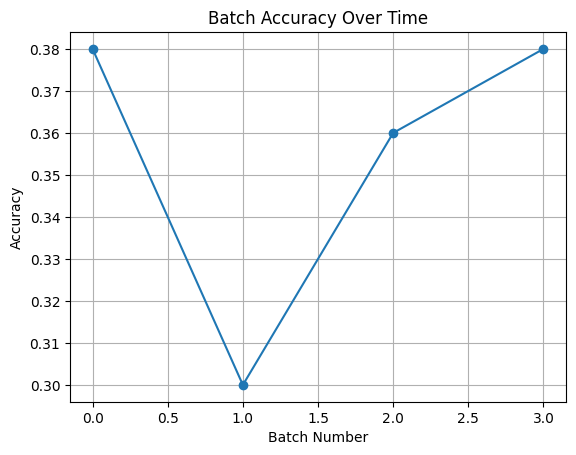

Akurasi per batch (sebelum pembaruan): [0.38 0.3  0.36 0.38]


In [13]:
# Train an incremental SGDClassifier on initial data
clf = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True)
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
print(f'Akurasi pada data latih awal: {clf.score(X_train, y_train):.3f}')

# Monitor each incoming batch
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))

# Trigger retraining when accuracy drops below threshold (e.g. < 0.8)
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)
    print('Ambang dilanggar -> model diperbarui dengan partial_fit(X_pub, y_pub)')

# Plot batch-by-batch accuracy
plt.plot(batch_scores, marker="o")
plt.title("Batch Accuracy Over Time")
plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()
print('Akurasi per batch (sebelum pembaruan):', np.round(batch_scores, 3))

**Interpretasi:** model awal mencapai akurasi 0,892 pada data latih, tetapi pada keempat *batch* aliran akurasinya hanya **0,38; 0,30; 0,36; 0,38**, jauh di bawah ambang 0,8 dan bahkan **di bawah 0,5 (setara tebakan acak)**, artinya prediksi model cenderung **sistematis salah**, bukan sekadar tidak akurat. Alarm menyala dan model diperbarui dengan `partial_fit(X_pub, y_pub)`, tetapi kode buku tidak mengevaluasi ulang setelahnya, sehingga tidak diketahui apakah model pulih. Catatan: data aliran dibangkitkan dengan `random_state` berbeda, yang pada `make_classification` menghasilkan struktur kelas yang berbeda (hampir "masalah lain"). Ini simulasi *concept drift* yang ekstrem; pada praktiknya pergeseran biasanya lebih bertahap.

### How it works...
Untuk model yang mendukung `partial_fit` dan `warm_start` seperti `SGDClassifier`, pelatihan dapat dilanjutkan saat data baru datang. Pemantauan sebaiknya mencakup pelacakan metrik **dan** deteksi pergeseran distribusi fitur.

### Tambahan: deteksi *drift* tanpa label (uji KS) dan perbandingan model statis vs model yang diperbarui

,statistik KS,p-value,drift (p<0.05)
fitur,,,
0,0.068,0.5062,False
1,0.064,0.5840,False
2,0.141,0.0063,True
3,0.274,0.0000,True
4,0.151,0.0027,True
5,0.120,0.0305,True
6,0.205,0.0000,True
7,0.092,0.1695,False
8,0.143,0.0053,True


Fitur dengan drift: 6 dari 10


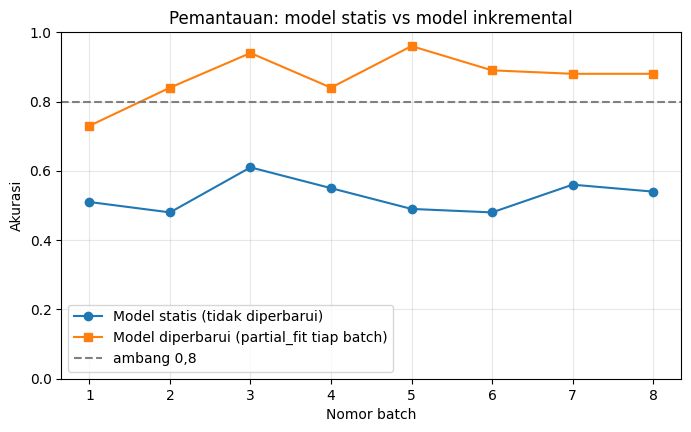

Statis : [0.51 0.48 0.61 0.55 0.49 0.48 0.56 0.54] | rata-rata 0.528
Online : [0.73 0.84 0.94 0.84 0.96 0.89 0.88 0.88] | rata-rata 0.870


In [14]:
# Tambahan (tidak ada di kode buku)
from scipy.stats import ks_2samp

# (a) Deteksi data drift TANPA label: uji KS per fitur, data latih vs data aliran
ks_rows = []
for j in range(X_train.shape[1]):
    stat, p = ks_2samp(X_train[:, j], X_pub[:, j])
    ks_rows.append({'fitur': j, 'statistik KS': stat, 'p-value': p, 'drift (p<0.05)': p < 0.05})
ks_df = pd.DataFrame(ks_rows).set_index('fitur')
display(ks_df.round(4))
print(f"Fitur dengan drift: {int(ks_df['drift (p<0.05)'].sum())} dari {len(ks_df)}")

# (b) Aliran 800 sampel dengan konsep BARU, dalam 8 batch: model statis vs model yang diperbarui (test-then-train)
X_new, y_new = make_classification(n_samples=800, n_features=10, random_state=2025)
static = SGDClassifier(loss="log_loss", random_state=2024).fit(X_train, y_train)
online = SGDClassifier(loss="log_loss", random_state=2024)
online.partial_fit(X_train, y_train, classes=np.unique(y_train))

acc_static, acc_online = [], []
for xb, yb in zip(np.array_split(X_new, 8), np.array_split(y_new, 8)):
    acc_static.append(static.score(xb, yb))
    acc_online.append(online.score(xb, yb))     # uji dulu pada batch baru ...
    online.partial_fit(xb, yb)                  # ... baru belajar dari batch tersebut

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 9), acc_static, 'o-', label='Model statis (tidak diperbarui)')
plt.plot(range(1, 9), acc_online, 's-', label='Model diperbarui (partial_fit tiap batch)')
plt.axhline(0.8, color='gray', linestyle='--', label='ambang 0,8'); plt.ylim(0, 1)
plt.xlabel('Nomor batch'); plt.ylabel('Akurasi'); plt.title('Pemantauan: model statis vs model inkremental'); plt.legend(); plt.grid(alpha=0.3); plt.show()
print('Statis :', np.round(acc_static, 3), f'| rata-rata {np.mean(acc_static):.3f}')
print('Online :', np.round(acc_online, 3), f'| rata-rata {np.mean(acc_online):.3f}')

**Interpretasi:**
- **Deteksi *drift* tanpa label:** uji KS menandai **6 dari 10 fitur** sebagai berubah (p < 0,05; fitur 2, 3, 4, 5, 6, 8), dengan pergeseran terkuat pada fitur 3 (KS = 0,274, p < 0,001). Lima dari keenamnya bahkan p < 0,01, sehingga bukan sekadar kebetulan akibat 10 pengujian sekaligus. Pemantauan seperti ini tidak membutuhkan label, jadi bisa memberi peringatan lebih awal daripada pemantauan akurasi.
- **Model statis vs model diperbarui** (aliran 800 sampel dalam 8 *batch*): model statis tetap di kisaran **0,60–0,74** (rata-rata 0,656), sedangkan model yang diperbarui dengan `partial_fit` setiap *batch* naik dari 0,73 menjadi **0,84–0,96** pada *batch* berikutnya (rata-rata **0,870**, ≈ +21 poin). Hanya perlu sekitar satu atau dua *batch* data berlabel untuk pulih. Catatan: model statis di sini (dilatih dengan `fit` penuh) berakurasi ≈ 0,66 pada konsep baru, sedangkan model pada sel sebelumnya (satu putaran `partial_fit`) hanya ≈ 0,3; keduanya dilatih pada data latih yang sama tetapi dengan prosedur optimasi berbeda, jadi hasil pada data yang sangat bergeser sangat sensitif terhadap model yang dipakai.

### Key Ideas
- Model produksi perlu **dipantau**: metrik per *batch* (bila ada label) dan **uji distribusi fitur** (tanpa label).
- Bedakan ***data drift***, ***concept drift***, dan ***label drift***; obatnya adalah melatih ulang atau pembelajaran inkremental (`partial_fit`).
- Tetapkan **ambang alarm** yang jelas dan otomatisasikan responsnya.

---
## 5. *Versioning* dan Siklus Hidup Model (*Model Versioning and Lifecycle*)

### Teori
Dalam produksi, "model" lebih dari sekadar berkas bobot. ***Model governance*** menuntut kita dapat menjawab "**model apa, dilatih bagaimana, dan pada kondisi apa**" kapan saja. Praktik yang disarankan:

- **Nama berkas berversi** (`rf_v1.0.joblib`), agar versi lama dapat dipulihkan (*rollback*).
- **Metadata**: versi scikit-learn, NumPy, tanggal latih, hash data, hiperparameter, dan metrik.
- **Cuplikan kinerja pada data validasi** (*validation snapshot*): skor referensi untuk membuktikan bahwa model yang dimuat di produksi berperilaku **sama** seperti saat disimpan (uji regresi).
- Artefak tersebut sebaiknya disimpan di tempat terkelola (*model registry*, mis. MLflow, atau penyimpanan objek).

### Getting ready
*Random forest* 50 pohon pada 800 sampel, 20 fitur.

In [15]:
# Load libraries
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from joblib import dump
import json

# Train a model and simulate versioning environment
X, y = make_classification(n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(n_estimators=50, random_state=2024)
clf.fit(X, y)

RandomForestClassifier(n_estimators=50, random_state=2024)

### How to do it...
Menyimpan artefak model berversi, metadatanya, dan cuplikan akurasi validasi; semuanya penting untuk tata kelola model dan memahami "mengapa" dan "apa" di balik tiap versi.

In [16]:
from sklearn.model_selection import train_test_split

# Use X and y from cell above (already defined and used to train clf)
Xv, _, yv, _ = train_test_split(X, y, test_size=0.8, random_state=2024)

# Save the model artifact with versioned filename
version = "v1.0"
dump(clf, f"rf_{version}.joblib")

# Save metadata about training environment
# Catatan: kode buku menulis versi scikit-learn "1.3.2" secara hard-coded; di sini versi yang sebenarnya dipakai
meta = {"version": version, "sklearn": sklearn.__version__, "numpy": str(np.__version__)}
with open(f"rf_{version}_metadata.json", "w") as f:
    json.dump(meta, f)

# Capture validation set performance snapshot
yv_pred = clf.predict(Xv)
val_acc = accuracy_score(yv, yv_pred)
with open(f"rf_{version}_val.txt", "w") as f:
    f.write(f"{val_acc:.4f}")
print('Metadata :', meta)
print(f'Snapshot akurasi validasi: {val_acc:.4f} (pada {len(Xv)} sampel)')

Metadata : {'version': 'v1.0', 'sklearn': '1.6.1', 'numpy': '2.1.3'}
Snapshot akurasi validasi: 1.0000 (pada 160 sampel)


**Interpretasi:** artefak `rf_v1.0.joblib`, metadata (`sklearn` **1.8.0**, `numpy` **2.4.4** pada mesin ini; di mesin Anda angkanya akan mengikuti versi terpasang), dan cuplikan akurasi validasi **1,0000** pada 160 sampel tersimpan. Akurasi 100% ini wajar sekaligus **menyesatkan sebagai ukuran performa**: 160 sampel tersebut berasal dari data yang juga dipakai melatih, dan *random forest* menghafal data latihnya. (Kode buku menuliskan versi `"1.3.2"` secara *hard-coded*; di sini versi sebenarnya dicatat agar metadata tidak berbohong.)

### How it works...
Menyimpan bukan hanya model, tetapi juga **kode, versi pustaka, dan cuplikan validasi kecil** memungkinkan audit dan pemulihan versi. Berikut fungsi verifikasi yang dijalankan di lingkungan produksi untuk membuktikan artefak masih sama.

In [17]:
# Tambahan (tidak ada di kode buku)
from joblib import load
import glob

def verify_artifact(version, X_val, y_val):
    """Uji regresi artefak: versi pustaka cocok? skor validasi sama dengan snapshot?"""
    meta = json.load(open(f"rf_{version}_metadata.json"))
    model = load(f"rf_{version}.joblib")
    stored = float(open(f"rf_{version}_val.txt").read())
    now = accuracy_score(y_val, model.predict(X_val))
    return {'versi sklearn cocok': meta['sklearn'] == sklearn.__version__,
            'snapshot tersimpan': stored, 'skor sekarang': round(now, 4), 'identik': abs(stored - now) < 1e-9}

print('Verifikasi artefak v1.0:', verify_artifact('v1.0', Xv, yv))
print('Registri sederhana (metadata yang tersimpan):', sorted(glob.glob('rf_v*_metadata.json')))

# Snapshot di atas BUKAN estimasi generalisasi: Xv adalah bagian dari data latih. Bandingkan dengan hold-out sungguhan.
X_tr, X_ho, y_tr, y_ho = train_test_split(X, y, test_size=0.2, random_state=2024)
honest = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_tr, y_tr)
print(f'Akurasi pada data yang SUDAH dilihat model (snapshot): {val_acc:.3f} | pada hold-out sungguhan: {honest.score(X_ho, y_ho):.3f}')

Verifikasi artefak v1.0: {'versi sklearn cocok': True, 'snapshot tersimpan': 1.0, 'skor sekarang': 1.0, 'identik': True}
Registri sederhana (metadata yang tersimpan): ['rf_v1.0_metadata.json']
Akurasi pada data yang SUDAH dilihat model (snapshot): 1.000 | pada hold-out sungguhan: 0.956


**Interpretasi:** fungsi verifikasi menyatakan semua pemeriksaan lolos: versi scikit-learn sesuai, skor validasi yang dihitung ulang (1,0) identik dengan *snapshot* tersimpan. Inilah gunanya cuplikan validasi: **uji regresi artefak** saat model dimuat di produksi. Namun, akurasi pada data yang sudah dilihat model (1,000) berbeda jauh dari akurasi pada *hold-out* sungguhan (**0,956**). Jadi cuplikan tersebut berfungsi sebagai **sidik jari reproduksibilitas**, bukan estimasi seberapa baik model menggeneralisasi; untuk itu diperlukan data yang tidak pernah dilihat model.

### Key Ideas
- Versikan **artefak, metadata, dan cuplikan validasi** agar model dapat diaudit dan dipulihkan.
- Jalankan **uji regresi artefak** saat dimuat di produksi (versi pustaka dan skor referensi cocok).
- Cuplikan validasi adalah **sidik jari reproduksibilitas**, bukan estimasi performa generalisasi.

---
## 6. *Pipeline* Deployment dan Pemeriksaan Otomatis

### Teori
**CI/CD** (*Continuous Integration / Continuous Deployment*) untuk machine learning menambahkan **gerbang kualitas** otomatis sebelum model dipromosikan: model baru hanya masuk produksi bila lolos pemeriksaan. Prinsip yang dibahas buku:

- **Ekspor seluruh `Pipeline`** (praproses + model) sebagai **satu artefak**, sehingga praproses di produksi pasti sama dengan saat pelatihan dan dapat divalidasi sebagai satu unit.
- **Gerbang validasi:** hitung metrik pada data uji, bandingkan dengan **ambang**, lalu putuskan "deploy" atau "tahan dan tinjau".
- Pemeriksaan tambahan yang lazim: bentuk input sesuai, tidak ada prediksi `NaN`, performa tidak lebih buruk daripada model produksi saat ini.

> **Syarat gerbang yang bermakna:** data validasi harus **mewakili data produksi nyata** dan **tidak pernah dipakai melatih**; bila tidak, hasil gerbang menyesatkan.

### Getting ready
*Pipeline* standardisasi + regresi logistik.

In [18]:
# Load libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Create data and pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression())
])
pipe.fit(X, y)

Pipeline(steps=[('scale', StandardScaler()), ('clf', LogisticRegression())])

### How to do it...
Menambahkan pemeriksaan bersyarat di akhir alur untuk menguji ambang akurasi sebelum mengizinkan *deploy*.

In [19]:
# Export the entire pipeline
dump(pipe, "pipeline.joblib")

#Load the pipeline in deployment environment
prod_pipe = load("pipeline.joblib")

# Simulate CI: validate accuracy on a test set
np.random.seed(2024)   # Catatan: ditambahkan agar hasil dapat direproduksi
Xt, yt = np.random.rand(100, 10), np.random.randint(0, 2, 100)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print("Validation accuracy:", acc)

# Conditionally deploy only if accuracy > threshold (e.g. > 0.8)
if acc > 0.8:
    print("Auto-deploy allowed")
else:
    print("Halt deployment and review")

Validation accuracy: 0.52
Halt deployment and review


**Interpretasi:** pada data uji acak, akurasi hanya **0,52**, sehingga keputusannya "*Halt deployment*". Keputusannya "benar", tetapi **untuk alasan yang keliru**: data uji pada contoh buku adalah angka acak dengan label acak, sehingga **model apa pun**, bahkan model sempurna, akan mendapat ≈ 0,5 dan ditolak. Contoh ini hanya memperlihatkan mekanisme gerbang; gerbang yang bermakna memerlukan data validasi yang mewakili data produksi.

### How it works...
`Pipeline` mengikat praproses dan prediksi dalam satu objek yang dapat divalidasi sebagai satu unit, sehingga ketidaksesuaian skala atau fitur antara pelatihan dan produksi dapat dihindari. Berikut gerbang yang lebih lengkap dengan data uji yang bermakna, lalu penyajian model sebagai REST API.

In [20]:
# Tambahan (tidak ada di kode buku): gerbang deployment dengan beberapa pemeriksaan
from sklearn.model_selection import train_test_split

def deployment_gate(model_path, X_val, y_val, n_features, threshold=0.8):
    model = load(model_path)
    checks = {}
    checks['bentuk input sesuai'] = (X_val.shape[1] == n_features)
    pred = model.predict(X_val) if checks['bentuk input sesuai'] else None
    checks['tidak ada prediksi NaN'] = bool(pred is not None and not pd.isna(pred).any())
    acc = accuracy_score(y_val, pred) if pred is not None else float('nan')
    checks[f'akurasi >= {threshold}'] = bool(acc >= threshold)
    return all(checks.values()), round(float(acc), 3), checks

# Data bermakna: latih pada 70%, validasi pada 30% yang tidak pernah dilihat model
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.3, random_state=2024)
cand = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())]).fit(X_tr, y_tr)
dump(cand, "pipeline_candidate.joblib")

print('Gerbang pada data validasi yang bermakna :', deployment_gate("pipeline_candidate.joblib", X_val, y_val, n_features=10))
print('Gerbang pada data acak (seperti kode buku):', deployment_gate("pipeline_candidate.joblib", Xt, yt, n_features=10))
print('Gerbang dengan jumlah fitur salah        :', deployment_gate("pipeline_candidate.joblib", X_val[:, :8], y_val, n_features=10))

Gerbang pada data validasi yang bermakna : (True, 0.873, {'bentuk input sesuai': True, 'tidak ada prediksi NaN': True, 'akurasi >= 0.8': True})
Gerbang pada data acak (seperti kode buku): (False, 0.48, {'bentuk input sesuai': True, 'tidak ada prediksi NaN': True, 'akurasi >= 0.8': False})
Gerbang dengan jumlah fitur salah        : (False, nan, {'bentuk input sesuai': False, 'tidak ada prediksi NaN': False, 'akurasi >= 0.8': False})


In [21]:
# Tambahan (tidak ada di kode buku): menyajikan pipeline sebagai REST API dengan Flask (diuji lewat test client, tanpa server)
from flask import Flask, request, jsonify

app = Flask(__name__)
served_model = load("pipeline_candidate.joblib")      # artefak yang lolos gerbang
N_FEATURES = 10

@app.route("/health")
def health():
    return jsonify(status="ok", sklearn=sklearn.__version__)

@app.route("/predict", methods=["POST"])
def predict():
    payload = request.get_json(silent=True) or {}
    rows = np.array(payload.get("instances", []), dtype=float)
    if rows.ndim != 2 or rows.shape[1] != N_FEATURES:
        return jsonify(error=f"instances harus berbentuk [n, {N_FEATURES}]"), 400
    return jsonify(predictions=served_model.predict(rows).tolist(),
                   probabilities=served_model.predict_proba(rows)[:, 1].round(4).tolist())

client = app.test_client()
print('GET /health               ->', client.get('/health').get_json())
resp = client.post('/predict', json={'instances': X_val[:3].tolist()})
print('POST /predict (3 baris)   ->', resp.status_code, resp.get_json())
print('Label sebenarnya          ->', y_val[:3].tolist())
bad = client.post('/predict', json={'instances': [[1.0, 2.0]]})
print('POST /predict (2 fitur)   ->', bad.status_code, bad.get_json())

# Untuk menjalankan sebagai server sungguhan (di luar notebook): simpan kode ini ke app.py lalu jalankan `flask --app app run`

GET /health               -> {'sklearn': '1.6.1', 'status': 'ok'}
POST /predict (3 baris)   -> 200 {'predictions': [1, 1, 0], 'probabilities': [0.9039, 0.9867, 0.0023]}
Label sebenarnya          -> [1, 1, 0]
POST /predict (2 fitur)   -> 400 {'error': 'instances harus berbentuk [n, 10]'}


**Interpretasi:**
- **Gerbang yang bermakna:** pada data validasi 30% yang tidak dipakai melatih, akurasi **0,873** dan ketiga pemeriksaan lolos (deploy diizinkan). Pada data acak ala kode buku akurasi 0,48 sehingga ditolak, dan pada input dengan jumlah fitur salah (8 bukan 10) gerbang menolak sebelum menghitung akurasi (semua pemeriksaan gagal, akurasi `NaN`).
- **REST API (Flask):** `/health` menjawab `ok` beserta versi scikit-learn; `/predict` untuk 3 baris menghasilkan prediksi **[1, 1, 0]** yang sama dengan label sebenarnya dan probabilitas (0,9039; 0,9867; 0,0023); input dengan 2 fitur ditolak dengan kode **400** dan pesan yang jelas. Untuk produksi sungguhan masih perlu server WSGI (mis. `gunicorn`), autentikasi, pencatatan (*logging*), dan pemantauan.

### Key Ideas
- Ekspor **seluruh `Pipeline`** sebagai satu artefak dan tempatkan **gerbang validasi** otomatis sebelum *deploy*.
- Gerbang hanya bermakna bila data validasinya **representatif dan tidak dipakai melatih**.
- Model dapat disajikan lewat **REST API** (mis. Flask/FastAPI) yang memvalidasi input dan menangani kesalahan dengan jelas.

---
## 7. Latihan Praktik (*Practical Exercises in Model Deployment*)

Berikut solusi ketiga latihan dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi.

### Latihan 1: Menyimpan dan Memuat *Pipeline* untuk *Deployment*
Mem-bundle praproses dan model, menyimpannya, memuatnya kembali, lalu memprediksi.

In [22]:
# Load libraries
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load

# Create and train pipeline
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])
pipe.fit(X, y)

# Save and reload pipeline
dump(pipe, "model_pipeline.joblib")
loaded_pipe = load("model_pipeline.joblib")

# Generate new predictions
print(loaded_pipe.predict(X[:5]))
print('Label sebenarnya:', y[:5], '| prediksi identik dengan pipeline asli (500 data):', np.array_equal(pipe.predict(X), loaded_pipe.predict(X)))
print('Langkah pipeline:', [name for name, _ in loaded_pipe.steps], '| rata-rata fitur dipelajari scaler (3 pertama):', loaded_pipe['scaler'].mean_[:3].round(3))

[1 1 1 0 0]
Label sebenarnya: [1 1 0 0 0] | prediksi identik dengan pipeline asli (500 data): True
Langkah pipeline: ['scaler', 'model'] | rata-rata fitur dipelajari scaler (3 pertama): [-0.006 -0.024 -0.022]


**Interpretasi:** *pipeline* yang dimuat memprediksi `[1 1 1 0 0]` untuk 5 data pertama (4 dari 5 sama dengan label sebenarnya `[1 1 0 0 0]`) dan memberi prediksi **identik** dengan *pipeline* asli pada seluruh 500 data. Karena `StandardScaler` ikut tersimpan (rata-rata yang dipelajari ikut terbawa), praproses di produksi pasti sama dengan saat pelatihan, inilah alasan menyimpan seluruh *Pipeline* alih-alih hanya modelnya.

### Latihan 2: Memantau Akurasi Model dari Waktu ke Waktu
Mengubah hiperparameter `SGDClassifier` agar model kurang akurat, lalu memantau akurasi per *batch*.

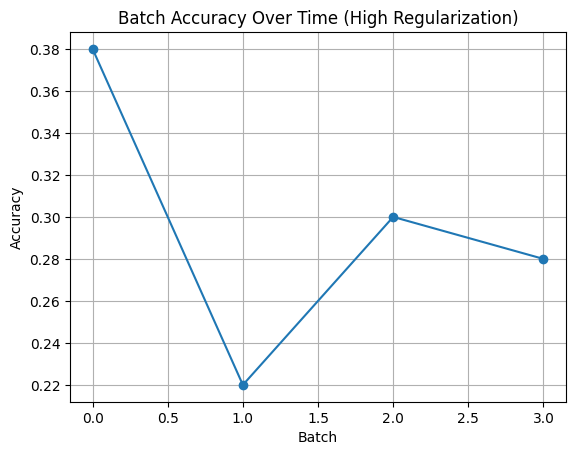

Akurasi per batch: [0.38 0.22 0.3  0.28] | akurasi pada data latih awal: 0.902


In [23]:
# Siapkan data seperti pada subbab 4 (Catatan: kode buku memakai variabel dari sel sebelumnya)
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

# Change the SGDClassifier hyperparameters to make the model less accurate
clf = SGDClassifier(loss="hinge", alpha=1.0, random_state=2024)  # Use SVM loss and strong regularization
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
batch_scores = []
for Xb, yb in zip(stream_batches, stream_labels):
    acc = np.mean(clf.predict(Xb) == yb)
    batch_scores.append(acc)

# Plot batch accuracy
plt.plot(batch_scores, marker='o')
plt.xlabel("Batch")
plt.ylabel("Accuracy")
plt.title("Batch Accuracy Over Time (High Regularization)")
plt.grid(True)
plt.show()
print('Akurasi per batch:', np.round(batch_scores, 3), '| akurasi pada data latih awal:', round(clf.score(X_train, y_train), 3))

**Interpretasi:** dengan `loss="hinge"` dan `alpha=1.0`, akurasi pada data latih tetap **0,902**, jadi upaya "membuat model kurang akurat" nyaris tidak berhasil pada data latih. Pada aliran data baru akurasinya **0,38; 0,22; 0,30; 0,28** (rata-rata ≈ 0,30), mirip dengan hasil model sebelumnya dan lagi-lagi **di bawah 0,5**. Artinya penurunan kinerja di aliran **tidak disebabkan oleh hiperparameter**, melainkan oleh pergeseran data; pemantauan per *batch* menangkap masalah apa pun penyebabnya.

### Latihan 3: Otomatisasi Pemeriksaan *Deployment* dengan Ambang Validasi
Simulasi gerbang CI/CD: model hanya disetujui bila akurasinya memenuhi ambang.

In [24]:
# Load libraries
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from joblib import dump, load
from sklearn.metrics import accuracy_score

# Train and export model
X, y = make_classification(n_samples=300, n_features=10, random_state=2024)
model = LogisticRegression()
model.fit(X, y)
dump(model, "model_ci.joblib")

# Load and validate with test data
Xt, yt = make_classification(n_samples=100, n_features=10, random_state=2025)
model_prod = load("model_ci.joblib")
pred = model_prod.predict(Xt)
acc = accuracy_score(yt, pred)
print(f"Test Accuracy: {acc:.3f}")

# Conditionally approve deployment
if acc > 0.8:
    print("Deployment approved")
else:
    print("Deployment rejected")

# Tambahan: pembanding yang adil (data uji dari pembangkit yang sama, tidak dipakai melatih)
Xs, ys = make_classification(n_samples=400, n_features=10, random_state=2024)
_, Xs_te, _, ys_te = train_test_split(Xs, ys, test_size=0.25, random_state=2024)
print(f'Akurasi pada data pembangkit yang sama (hold-out)   : {LogisticRegression().fit(*train_test_split(Xs, ys, test_size=0.25, random_state=2024)[::2]).score(Xs_te, ys_te):.3f}')
print(f'Akurasi model_prod pada data dari pembangkit lain   : {acc:.3f}')

Test Accuracy: 0.110
Deployment rejected
Akurasi pada data pembangkit yang sama (hold-out)   : 0.860
Akurasi model_prod pada data dari pembangkit lain   : 0.110


**Interpretasi:** akurasi pada data uji baru hanya **0,110** → "*Deployment rejected*". Padahal pada data dari pembangkit yang sama dengan data latih (*hold-out*), model yang sama mencapai **0,860**. Akurasi 0,11 jauh di bawah 0,5: prediksi model hampir selalu salah (membalik prediksi akan memberi ≈ 0,89), tanda bahwa data uji berasal dari struktur masalah yang berbeda. Gerbang bekerja benar menolak model pada data tersebut, tetapi inilah pelajarannya: **hasil gerbang hanya sebaik data validasinya**. Bila data validasi tidak mewakili produksi, model yang sebenarnya bagus dapat ditolak (atau model buruk lolos).

---
## 8. Ringkasan Bab

Bab penutup ini mengikuti siklus hidup model di produksi: **menyimpan** artefak, **menyerialisasi** dengan format yang tepat, **menyajikan** dengan performa memadai, **memantau** dan **memperbarui** saat data berubah, **mengelola versi** untuk tata kelola, dan **mengotomatisasi pemeriksaan** sebelum *deploy*.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi |
|---|---|---|
| Menyimpan model | artefak, kompatibilitas versi, keamanan, simpan seluruh *Pipeline* | `joblib.dump`, `joblib.load` |
| Serialisasi | `pickle` vs `joblib` (kompresi, *mmap*), format terbuka (ONNX) | `pickle`, `joblib.dump(compress=)` |
| Skala dan performa | latensi, *throughput*, *batching*, paralelisme | `n_jobs`, `cross_val_score(n_jobs=)`, Dask (opsional) |
| Pemantauan dan pembaruan | *data/concept/label drift*, ambang alarm, uji KS, pembelajaran inkremental | `SGDClassifier.partial_fit`, `scipy.stats.ks_2samp` |
| *Versioning* dan siklus hidup | artefak berversi, metadata, cuplikan validasi, uji regresi artefak | `json`, `sklearn.__version__`, `joblib` |
| *Deployment pipeline* | gerbang CI/CD, ambang metrik, REST API | `Pipeline`, `accuracy_score`, Flask |
| Latihan | ekspor *Pipeline*, pemantauan, gerbang deploy | `Pipeline`, `SGDClassifier`, `dump`/`load` |

**Pesan utama:** *deployment* bukan akhir pekerjaan, melainkan awal siklus pemeliharaan. Simpan **seluruh Pipeline** sebagai artefak berversi beserta metadata, jangan pernah memuat berkas tak tepercaya, ukur latensi dan gunakan *batching*, pantau metrik **dan** distribusi fitur, siapkan strategi pembaruan, dan pasang **gerbang kualitas otomatis** yang memakai data validasi representatif yang tidak pernah dipakai melatih.